# Elastic Net Regression: A Complete Job-Ready Guide

### Why Elastic Net?
In real-world Machine Learning, datasets often suffer from two major issues:
1. **High Dimensionality**: More features than observations ($p > n$).
2. **Multicollinearity**: Features are highly correlated with one another.

* **Lasso (L1)** performs feature selection but arbitrarily selects one feature from a group of correlated features and discards the rest.
* **Ridge (L2)** keeps all features but cannot shrink coefficients to exactly zero.
* **Elastic Net** combines both penalties, bringing the group selection capability of L1 while retaining the regularization stability of L2.

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.datasets import make_regression
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import ElasticNet, ElasticNetCV, Ridge, Lasso
from sklearn.metrics import mean_squared_error, r2_score

# Set random seed for reproducibility
np.random.seed(42)
print("Libraries successfully imported!")

Libraries successfully imported!


## 1. Data Simulation with Multicollinearity
Let's generate a synthetic dataset where we deliberately introduce highly correlated features to demonstrate the strength of Elastic Net.

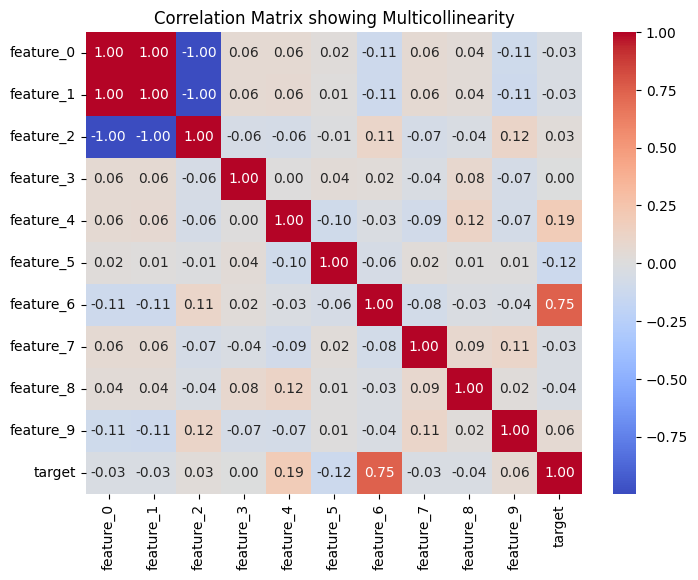

In [2]:
# Generate synthetic regression data
X, y, coef = make_regression(n_samples=200, n_features=10, n_informative=4, noise=1.5, coef=True, random_state=42)

# Create a DataFrame
columns = [f'feature_{i}' for i in range(10)]
df = pd.DataFrame(X, columns=columns)

# Artificially introduce strong multicollinearity
# feature_1 and feature_2 will be heavily correlated with feature_0
df['feature_1'] = df['feature_0'] * 0.95 + np.random.normal(0, 0.05, size=200)
df['feature_2'] = df['feature_0'] * -0.90 + np.random.normal(0, 0.05, size=200)

# Target variable
df['target'] = y

# Display correlation matrix heatmap
plt.figure(figsize=(8, 6))
sns.heatmap(df.corr(), annot=True, cmap='coolwarm', fmt='.2f')
plt.title("Correlation Matrix showing Multicollinearity")
plt.show()

## 2. Train-Test Split and Standardization
Always scale features when applying regularized models because regularization penalties are sensitive to the magnitude of the features.

In [3]:
X_train, X_test, y_train, y_test = train_test_split(
    df.drop('target', axis=1), df['target'], test_size=0.2, random_state=42
)

scaler = StandardScaler()
X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)

print(f"Training set shape: {X_train_scaled.shape}")
print(f"Testing set shape: {X_test_scaled.shape}")

Training set shape: (160, 10)
Testing set shape: (40, 10)


## 3. Tuning Hyperparameters using `ElasticNetCV`
Elastic Net has two crucial hyperparameters:
- `alpha` (overall penalty constant)
- `l1_ratio` (the mixing parameter: `0` for Ridge, `1` for Lasso, and anything in between for Elastic Net).

In [4]:
# Define search space
l1_ratios = [0.1, 0.3, 0.5, 0.7, 0.9, 0.95, 0.99, 1.0]

# Instantiate and fit ElasticNetCV
elastic_net_cv = ElasticNetCV(l1_ratio=l1_ratios, cv=5, random_state=42, n_jobs=-1)
elastic_net_cv.fit(X_train_scaled, y_train)

print(f"Optimal Alpha: {elastic_net_cv.alpha_:.4f}")
print(f"Optimal L1 Ratio: {elastic_net_cv.l1_ratio_:.4f}")

Optimal Alpha: 1.0807
Optimal L1 Ratio: 1.0000


/usr/local/lib/python3.13/dist-packages/sklearn/linear_model/_coordinate_descent.py:681: ConvergenceWarning: Objective did not converge. You might want to increase the number of iterations. Duality gap: 31.31590470217634, tolerance: 30.673057036400476
  model = cd_fast.enet_coordinate_descent_gram(
/usr/local/lib/python3.13/dist-packages/sklearn/linear_model/_coordinate_descent.py:681: ConvergenceWarning: Objective did not converge. You might want to increase the number of iterations. Duality gap: 38.226128688358585, tolerance: 30.673057036400476
  model = cd_fast.enet_coordinate_descent_gram(
/usr/local/lib/python3.13/dist-packages/sklearn/linear_model/_coordinate_descent.py:681: ConvergenceWarning: Objective did not converge. You might want to increase the number of iterations. Duality gap: 46.36300383451453, tolerance: 30.673057036400476
  model = cd_fast.enet_coordinate_descent_gram(
/usr/local/lib/python3.13/dist-packages/sklearn/linear_model/_coordinate_descent.py:681: Convergenc

## 4. Evaluation & Performance Comparison
Let's train Lasso, Ridge, and our optimized Elastic Net to evaluate performance metrics.

In [5]:
# Train models
models = {
    'Ridge': Ridge(alpha=1.0),
    'Lasso': Lasso(alpha=1.0),
    'ElasticNet (Optimized)': ElasticNet(alpha=elastic_net_cv.alpha_, l1_ratio=elastic_net_cv.l1_ratio_)
}

results = {}

for name, model in models.items():
    model.fit(X_train_scaled, y_train)
    preds = model.predict(X_test_scaled)
    mse = mean_squared_error(y_test, preds)
    r2 = r2_score(y_test, preds)
    results[name] = {'MSE': mse, 'R2': r2, 'Coefficients': model.coef_}
    print(f"{name:22} -> Test MSE: {mse:.4f} | R2 Score: {r2:.4f}")

Ridge                  -> Test MSE: 1785.2420 | R2 Score: 0.6053
Lasso                  -> Test MSE: 1804.2539 | R2 Score: 0.6011
ElasticNet (Optimized) -> Test MSE: 1806.9282 | R2 Score: 0.6005


## 5. Comparative Coefficient Analysis
Observe how each model handles multicollinearity. Note how Lasso completely zeroes out certain correlated variables, while Elastic Net stabilizes them.

,Feature,Ridge,Lasso,ElasticNet
0,feature_0,8.631368,1.147997,1.042041
1,feature_1,-1.105185,0.000000,0.000000
2,feature_2,5.166955,-0.000000,-0.000000
3,feature_3,-1.140753,-0.153966,-0.071962
4,feature_4,10.405565,9.377036,9.292282
5,feature_5,-4.733584,-3.817310,-3.743963
6,feature_6,38.504794,37.428025,37.324871
7,feature_7,0.352495,0.000000,0.000000
8,feature_8,-2.862062,-1.853400,-1.773894
9,feature_9,5.209119,4.316345,4.234581


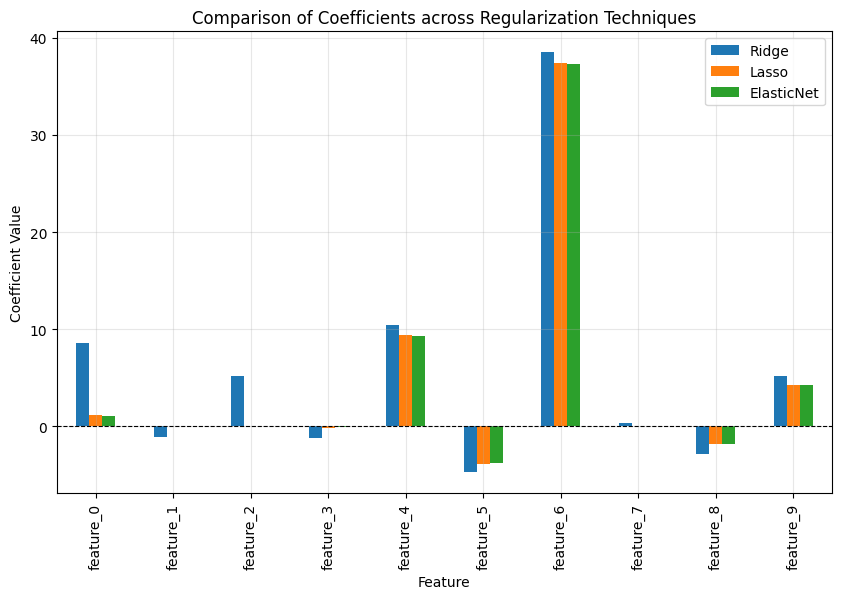

In [6]:
coef_df = pd.DataFrame({
    'Feature': columns,
    'Ridge': results['Ridge']['Coefficients'],
    'Lasso': results['Lasso']['Coefficients'],
    'ElasticNet': results['ElasticNet (Optimized)']['Coefficients']
})

display(coef_df)

# Plot Coefficients
coef_df.set_index('Feature').plot(kind='bar', figsize=(10, 6))
plt.title('Comparison of Coefficients across Regularization Techniques')
plt.ylabel('Coefficient Value')
plt.axhline(0, color='black', linestyle='--', linewidth=0.8)
plt.grid(True, alpha=0.3)
plt.show()